# 01 - Análisis exploratorio de datos (EDA)

Objetivo: entender los contratos de SECOP II descargados (etapa 1) y tomar las decisiones de alcance
antes de limpiar y construir etiquetas (etapas 2 y 3). Corresponde a la fase *Data Management* de
Ashmore et al. (2021).

Requisito: haber ejecutado `python scripts/descargar_datos.py`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from secopedia.configuracion import cargar_config, ruta
from secopedia.limpieza import limpiar_contratos
from secopedia.segmentos import nombre_segmento

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 120)
config = cargar_config()
carpeta_figuras = ruta(config["rutas"]["figuras"] + "/x").parent

contratos = pd.read_parquet(ruta(config["rutas"]["crudos"]))
contratos["segmento"] = contratos["codigo_de_categoria_principal"].str.extract(r"^V1\.(\d{2})", expand=False)
contratos["anio"] = contratos["fecha_de_firma"].dt.year
print(f"Contratos descargados: {len(contratos):,}")
print(f"Columnas: {list(contratos.columns)}")
contratos.head()

Matplotlib is building the font cache; this may take a moment.


Contratos descargados: 585,990
Columnas: ['id_contrato', 'objeto_del_contrato', 'descripcion_del_proceso', 'codigo_de_categoria_principal', 'tipo_de_contrato', 'fecha_de_firma', 'segmento', 'anio']


,id_contrato,objeto_del_contrato,descripcion_del_proceso,codigo_de_categoria_principal,tipo_de_contrato,fecha_de_firma,segmento,anio
0,CO1.PCCNTR.3279574,Delegación de funciones del Ministerio de Cultura al Distrito Especial; Industrial y Portuario de Barranquilla; para...,Delegación de funciones del Ministerio de Cultura al Distrito Especial; Industrial y Portuario de Barranquilla; para...,V1.93141700,Otro,2022-01-19 21:13:45.868,93,2022
1,CO1.PCCNTR.6239103,SUSCRIBIR UN CONTRATO DE FIDUCIA MERCANTIL PARA LA ADMINISTRACIÓN DE LOS RECURSOS DEL FONDO NACIONAL DE SALUD DE LAS...,SUSCRIBIR UN CONTRATO DE FIDUCIA MERCANTIL PARA LA ADMINISTRACIÓN DE LOS RECURSOS DEL FONDO NACIONAL DE SALUD DE LAS...,V1.93151500,Negocio fiduciario,2024-04-26 16:01:46.595,93,2024
2,CO1.PCCNTR.4515200,PRESTAR EL SERVICIO DE EDUCACIÓN INICIAL EN EL MARCO DE LA ATENCIÓN INTEGRAL EN HOGARES INFANTILES -HI-; DE CONFORMI...,PRESTAR EL SERVICIO DE EDUCACIÓN INICIAL EN EL MARCO DE LA ATENCIÓN INTEGRAL EN HOGARES INFANTILES -HI-; DE CONFORMI...,V1.93141500,Otro,2023-01-30 17:04:55.411,93,2023
3,CO1.PCCNTR.9375986,REEMPLAZO DEL PUENTE DOS RIOS EN EL\nDEPARTAMENTO DEL CAUCA EN EL MARCO DEL\nPROGRAMA VÍAS PARA LA PAZ.,REEMPLAZO DEL PUENTE DOS RIOS EN EL\nDEPARTAMENTO DEL CAUCA EN EL MARCO DEL\nPROGRAMA VÍAS PARA LA PAZ.,V1.72141000,Obra,2026-05-28 12:06:43.975,72,2026
4,CO1.PCCNTR.7570086,SUMINISTRO DE MATERIAL MEDICO QUIRURGICO E INSUMO FARMACEUTICO PARA EL AREA DE URGENCIAS DEL CENTRO DE SALUD FUNES,SUMINISTRO DE MATERIAL MEDICO QUIRURGICO E INSUMO FARMACEUTICO PARA EL AREA DE URGENCIAS DEL CENTRO DE SALUD FUNES,V1.42292900,Suministros,2025-02-27 09:58:32.165,42,2025


## 1. Contratos por tipo

                                contratos   pct
tipo_de_contrato                               
Decreto 092 de 2017                166270  28.4
Otro                               145750  24.9
Suministros                         96490  16.5
Compraventa                         68512  11.7
Obra                                37444   6.4
Arrendamiento de inmuebles          32725   5.6
Interventoría                        9012   1.5
Comodato                             8501   1.5
Seguros                              8289   1.4
Consultoría                          7991   1.4
Arrendamiento de muebles             1666   0.3
Servicios financieros                 937   0.2
Acuerdo Marco de Precios              670   0.1
Operaciones de Crédito Público        544   0.1
Venta muebles                         380   0.1
Asociación Público Privada            163   0.0
Negocio fiduciario                    153   0.0
No Especificado                       125   0.0
Concesión                             12

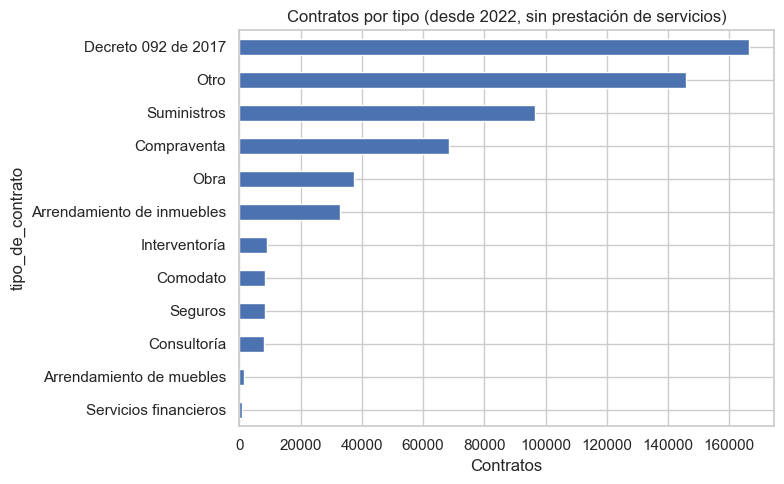

In [2]:
por_tipo = contratos["tipo_de_contrato"].value_counts()
tabla_tipos = pd.DataFrame({"contratos": por_tipo, "pct": (100 * por_tipo / len(contratos)).round(1)})
print(tabla_tipos.to_string())

fig, eje = plt.subplots(figsize=(8, 5))
por_tipo.head(12).sort_values().plot.barh(ax=eje, color="#4C72B0")
eje.set_xlabel("Contratos")
eje.set_title("Contratos por tipo (desde 2022, sin prestación de servicios)")
plt.tight_layout()
fig.savefig(carpeta_figuras / "contratos_por_tipo.png", dpi=150)

## 2. ¿La etiqueta es informativa en cada tipo de contrato?

En *Prestación de servicios* casi todo queda en `80111600`, por eso se excluyó. Aquí se revisa si
pasa lo mismo con "Otro" y "Decreto 092 de 2017". Se mide, por tipo: el porcentaje del código más
frecuente, el porcentaje de `80111600` y cuántos segmentos distintos aparecen.

In [3]:
def resumen_etiqueta(grupo):
    codigos = grupo["codigo_de_categoria_principal"]
    return pd.Series({
        "contratos": len(grupo),
        "codigo_mas_frecuente": codigos.mode().iat[0],
        "pct_codigo_mas_frecuente": round(100 * codigos.value_counts(normalize=True).iat[0], 1),
        "pct_80111600": round(100 * codigos.str.startswith("V1.801116").mean(), 1),
        "segmentos_distintos": grupo["segmento"].nunique(),
        "pct_segmento_80": round(100 * (grupo["segmento"] == "80").mean(), 1),
    })

tipos_principales = por_tipo.head(10).index
resumen_tipos = (
    contratos[contratos["tipo_de_contrato"].isin(tipos_principales)]
    .groupby("tipo_de_contrato")
    .apply(resumen_etiqueta, include_groups=False)
    .sort_values("contratos", ascending=False)
)
resumen_tipos

,contratos,codigo_mas_frecuente,pct_codigo_mas_frecuente,pct_80111600,segmentos_distintos,pct_segmento_80
tipo_de_contrato,,,,,,
Decreto 092 de 2017,166270,V1.80111600,20.3,25.2,56,35.9
Otro,145750,V1.93141500,15.7,4.7,56,17.3
Suministros,96490,UNSPECIFIED,2.7,1.2,56,2.9
Compraventa,68512,UNSPECIFIED,2.5,0.5,56,1.4
Obra,37444,UNSPECIFIED,15.4,0.7,55,3.0
Arrendamiento de inmuebles,32725,V1.80131500,56.2,0.7,36,95.1
Interventoría,9012,V1.81101500,39.5,2.3,35,36.2
Comodato,8501,V1.80131500,12.9,0.9,50,35.7
Seguros,8289,V1.84131500,37.4,1.0,32,2.2


In [4]:
for tipo in ["Otro", "Decreto 092 de 2017"]:
    muestra = contratos[contratos["tipo_de_contrato"] == tipo].sample(8, random_state=42)
    print(f"--- {tipo}")
    for _, fila in muestra.iterrows():
        print(f"  [{fila['segmento']}] {fila['objeto_del_contrato'][:110]}")

--- Otro
  [80] Aunar esfuerzos técnicos; administrativos y financieros para desarrollar el proyecto: CUALIFICACION TRANSVERSA
  [nan] PRESTACIÓN DE SERVICIOS DE SALUD PARA LAS PATOLOGÍAS OSTEOMUSCULARES Y DEL DESEMPEÑO FUNCIONAL Y REHABILITACIÓ
  [93] BRINDAR ATENCIÓN A LAS NIÑAS Y ADOLESCENTES QUE TIENEN UN PROCESO ADMINISTRATIVO DE RESTABLECIMIENTO DE DERECH
  [80] REALIZAR LOS AJUSTES A LOS DISEÑOS DE REDES SECAS DEL PARQUE FERNANDO GONZÁLEZ EN EL MUNICIPIO DE ENVIGADO; EN
  [93] Complementar la atención de niños y niñas a través de la entrega de alimentos para fortalecer el componente al
  [81] ESTUDIOS Y DISEÑOS PARA LA OPTIMIZACIÓN DEL ALCANTARILLADO SANITARIO; INCLUYE ACTUALIZACIÓN DEL CATASTRO DE RE
  [95] ADQUISICIÓN A TÍTULO DE COMPRAVENTA DEL BIEN INMUEBLE CON MATRÍCULA INMOBILIARIA NO. 024-14630; UBICADO EN LA 
  [72] AUNAR ESFUERZOS ENTRE EL MUNICIPIO DE SAN JERÓNIMO ANTIOQUIA Y LA JUNTA DE ACCIÓN COMUNAL VEREDA EL POMAR; PAR
--- Decreto 092 de 2017
  [92] AUNAR ESFUERZOS

## 3. Distribución de segmentos UNSPSC

In [5]:
por_segmento = contratos["segmento"].value_counts()
tabla_segmentos = pd.DataFrame({
    "nombre": [nombre_segmento(s) for s in por_segmento.index],
    "contratos": por_segmento,
    "pct": (100 * por_segmento / por_segmento.sum()).round(1),
})
minimo = config["etiquetas"]["min_ejemplos_por_segmento"]
print(f"Segmentos distintos: {len(por_segmento)}")
print(f"Segmentos con al menos {minimo:,} contratos: {(por_segmento >= minimo).sum()}")
print(f"Desbalance (mayor / menor de los que pasan el umbral): "
      f"{por_segmento.iat[0] / por_segmento[por_segmento >= minimo].iat[-1]:.1f}x")
tabla_segmentos.head(30)

Segmentos distintos: 56
Segmentos con al menos 4,000 contratos: 29
Desbalance (mayor / menor de los que pasan el umbral): 32.1x


,nombre,contratos,pct
segmento,,,
80,"Servicios de gestión, profesionales de empresa y administrativos",131808,23.1
93,Servicios políticos y de asuntos cívicos,63315,11.1
85,Servicios de salud,63239,11.1
72,"Servicios de edificación, construcción y mantenimiento",43589,7.6
81,"Servicios de ingeniería, investigación y tecnología",26272,4.6
43,Tecnologías de la información y telecomunicaciones,14666,2.6
42,"Equipo médico, accesorios y suministros",14302,2.5
84,Servicios financieros y de seguros,13219,2.3
90,"Servicios de viajes, alimentación, alojamiento y entretenimiento",12812,2.2


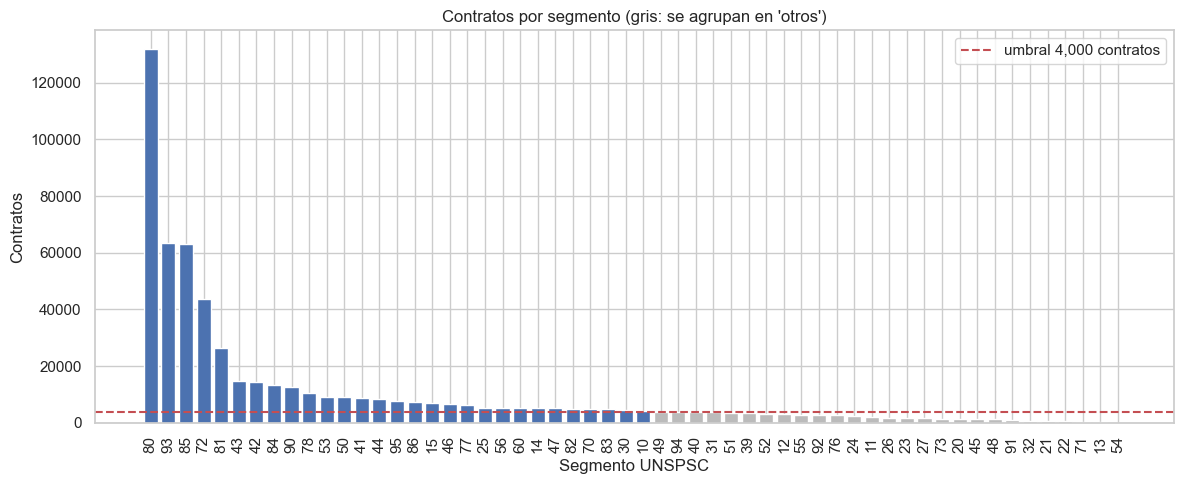

In [6]:
fig, eje = plt.subplots(figsize=(12, 5))
colores = ["#4C72B0" if n >= minimo else "#BBBBBB" for n in por_segmento]
eje.bar(por_segmento.index, por_segmento.values, color=colores)
eje.axhline(minimo, color="#C44E52", linestyle="--", label=f"umbral {minimo:,} contratos")
eje.set_xlabel("Segmento UNSPSC")
eje.set_ylabel("Contratos")
eje.set_title("Contratos por segmento (gris: se agrupan en 'otros')")
eje.legend()
plt.xticks(rotation=90)
plt.tight_layout()
fig.savefig(carpeta_figuras / "distribucion_segmentos.png", dpi=150)

## 4. Longitud de los textos

count    585990.0
mean         35.1
std          17.4
min           1.0
5%           13.0
50%          31.0
95%          70.0
99%          80.0
max         132.0


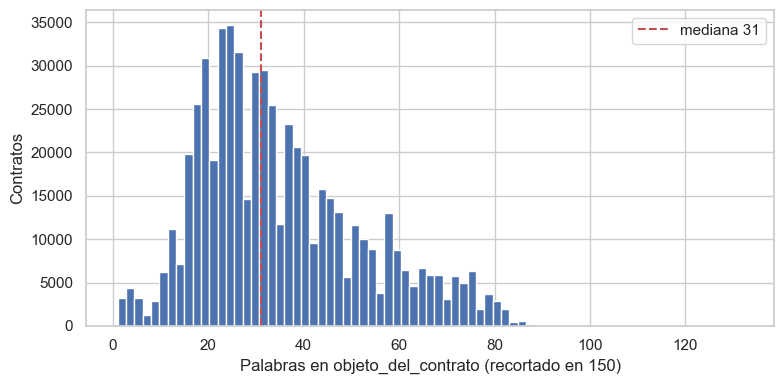

In [7]:
palabras = contratos["objeto_del_contrato"].fillna("").str.split().str.len()
print(palabras.describe(percentiles=[0.05, 0.5, 0.95, 0.99]).round(1).to_string())

fig, eje = plt.subplots(figsize=(8, 4))
eje.hist(palabras.clip(upper=150), bins=75, color="#4C72B0")
eje.axvline(palabras.median(), color="#C44E52", linestyle="--", label=f"mediana {palabras.median():.0f}")
eje.set_xlabel("Palabras en objeto_del_contrato (recortado en 150)")
eje.set_ylabel("Contratos")
eje.legend()
plt.tight_layout()
fig.savefig(carpeta_figuras / "longitud_textos.png", dpi=150)

## 5. Contratos por año (para la prueba temporal)

In [8]:
por_anio = contratos["anio"].value_counts().sort_index()
print(por_anio.to_string())
print(f"Fecha más reciente: {contratos['fecha_de_firma'].max()}")

anio
2022     92514
2023    112904
2024    124553
2025    147491
2026    108528
Fecha más reciente: 2026-11-15 12:06:49.292000


## 6. Calidad: códigos inválidos, duplicados y ruido de etiquetas

Se aplica la etapa 2 (`limpiar_contratos`) para cuantificar lo que se elimina en cada paso.

In [9]:
limpios, conflictos, reporte = limpiar_contratos(contratos, config["limpieza"])
reporte.como_tabla()

,paso,antes,despues,eliminados,pct_eliminado
0,texto vacío o con menos de 3 palabras,585990,582879,3111,0.53
1,código UNSPSC inválido,582879,568458,14421,2.47
2,fecha de firma inválida,568458,568458,0,0.00
3,duplicados de texto y código,568458,418534,149924,26.37
4,mismo texto con varios códigos (se deja uno),418534,394682,23852,5.70


In [10]:
print(f"Textos idénticos con segmentos distintos: {conflictos['clave_texto'].nunique():,}")
ejemplos = (
    conflictos.groupby("clave_texto")["segmento"]
    .agg(lambda s: sorted(set(s)))
    .reset_index()
    .assign(n=lambda d: d["segmento"].str.len())
    .sort_values("n", ascending=False)
    .head(10)
)
ejemplos

Textos idénticos con segmentos distintos: 9,837


,clave_texto,segmento,n
4427,entregar a titulo de comodato los bienes muebles para el fortalecimiento de los emprendimientos y unidades productiv...,"[11, 20, 21, 23, 24, 26, 27, 31, 40, 41, 45, 47, 48, 52, 56]",15
2260,complementar la atencion de ninos y ninas a traves de la entrega de alimentos para fortalecer el componente alimenta...,"[24, 41, 49, 70, 78, 80, 85, 93, 94]",9
9240,suministro de productos para el almacen,"[13, 14, 24, 42, 44, 47, 50, 55]",8
1845,aunar esfuerzos recursos y experiencia para brindar atencion a adultos mayores en estado de vulnerabilidad en centro...,"[14, 47, 53, 80, 93, 94]",6
3838,contrato de suministro,"[14, 41, 42, 51, 52, 85]",6
8786,suministro de materiales e insumos de ferreteria y mantenimiento para el hospital san rafael e s e,"[14, 53, 72, 81, 85, 93]",6
4604,gerencia integral de proyectos para participar en el festival expocundinamarca 2025 kuntur fest de acuerdo a las act...,"[56, 80, 81, 86, 90, 93]",6
4238,el comodatario recibe del comodante en prestamo de uso a titulo gratuito y con cargo a restituir bienes muebles de p...,"[32, 43, 44, 49, 52, 56]",6
4758,la adquisicion de materia prima e insumos para el proyecto productivo de panaderia del epms san gil inpec,"[10, 12, 24, 40, 50]",5
993,adquisicion de repuestos para equipos biomedicos y otros requeridos por el hospital santa ana de falan,"[26, 32, 42, 46, 81]",5


## 7. Conclusiones

*(Se completan después de ejecutar el notebook con los datos completos.)*